In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'training_data.csv')
df.head()

,hour,no2_ug_m3,total_intensity_veh_per_hr,hour_of_day
0,2026-11-24 16:00:00+00:00,44.16,5640.0,17
1,2026-11-24 21:00:00+00:00,22.66,1140.0,22
2,2026-11-25 18:00:00+00:00,15.57,2940.0,19
3,2026-11-25 20:00:00+00:00,12.01,2160.0,21
4,2026-11-25 21:00:00+00:00,11.71,1380.0,22


In [5]:
len(df)

25

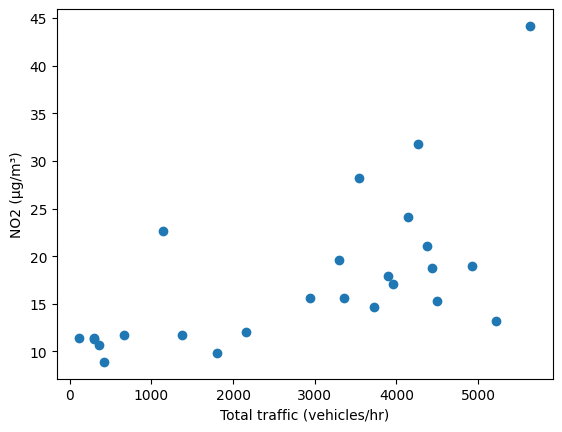

In [6]:
plt.scatter(df["total_intensity_veh_per_hr"], df["no2_ug_m3"])
plt.xlabel("Total traffic (vehicles/hr)")
plt.ylabel("NO2 (µg/m³)")
plt.show()

The dataset has 25 rows where NO₂ readings match traffic data from all four sites. The NO₂ table has more readings because its script fetches the last 10 hours each run, while traffic data only captures the hour when its script runs.

25 rows is roughly one day of data, which is too little to properly evaluate the model. R**2 and MAE will only show how well it fits the existing data, not how well it performs on new data. Running the traffic script more often wouldn't help because files are stored by hour and would overwrite each other. The dataset will grow over time. I'll mention this limitation in ADR-006.

The scatter plot shows a weak positive relationship: higher traffic generally comes with higher NO₂ levels, but there is a lot of variation. One point also has a strong influence on the trend line. With so little data, I can't confirm a clear linear relationship, but there is no reason to use a more complex model either. Simple linear regression is still a reasonable starting point.